In [1]:
# Cell 01 — Setup
# Output: Fixed settings and imports.
# Missing packages? Install requirements.txt once, then restart Python.
from pathlib import Path
import json,hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image
from scipy import ndimage as ndi
from scipy.optimize import linear_sum_assignment
from skimage import color
from sklearn.metrics import accuracy_score,balanced_accuracy_score,precision_score,recall_score,f1_score,roc_auc_score
from IPython.display import display,Math
OUT=Path('results');OUT.mkdir(exist_ok=True)
plt.rcParams.update({'figure.dpi':100,'font.size':10})
EPS=1e-12
CFG=dict(background_sigma=24.0,window=16,stride=8,bins=256,component_connectivity=8,
         minimum_positive_windows=1,object_iou=0.5)
# No test-image tuning. Keep the chosen pipeline and training templates.
# The stride is 8 so the 16-pixel windows overlap. The final rows/columns cover the edges.
# Keep all positive components. No size filter is tuned on this new image.
def savefig(name):
    plt.tight_layout();plt.savefig(OUT/f'{name}.png',dpi=160,bbox_inches='tight');plt.show();plt.close()
def table(df,name):
    df.to_csv(OUT/f'{name}.csv',index=False);display(df)
table(pd.DataFrame([CFG]),'configuration')


,background_sigma,window,stride,bins,component_connectivity,minimum_positive_windows,object_iou
0,24.0,16,8,256,8,1,0.5


In [2]:
# Cell 02 — What this new test does
# Output: Input provenance and a clear no-GT prediction rule.
manifest=json.loads(Path('input_manifest.json').read_text())
training_frames=pd.read_csv('training_frames.csv');training_patches=pd.read_csv('training_patches.csv')
assert len(training_frames)==60 and set(training_frames.split)=={'train'}
assert set(training_patches.split)=={'train'}
assert manifest['sequence']!='0000000367_0000000000'
assert manifest['sha256'] not in set(training_frames.sha256)
print('New image:',manifest['filename'])
print('Selection:',manifest['selection'])
print('The image is from a sequence not used by this model before.')
print('Predict first. Read this image\'s GT only after saving predictions.')
print('We test two fixed cases: an unused animal sequence and an unused human sequence.')
print('Two cases can show failures. They cannot measure a general detection accuracy.')
print('Class format source: https://sites.google.com/view/elizabethbondi/dataset')
print('class=0: animal; class=1: human. Humans are not animal targets in this experiment.')


New image: 0000000351_0000000000_0000000071.jpg
Selection: Middle filename of an unused animal sequence; no detection scores used. Negative human-sequence case retained separately.
The image is from a sequence not used by this model before.
Predict first. Read this image's GT only after saving predictions.
We test two fixed cases: an unused animal sequence and an unused human sequence.
Two cases can show failures. They cannot measure a general detection accuracy.
Class format source: https://sites.google.com/view/elizabethbondi/dataset
class=0: animal; class=1: human. Humans are not animal targets in this experiment.


In [3]:
# Cell 03 — Pipeline and matching formulas
# Output: Separate formulas for the fixed pipeline and the nearest-template decision.
display(Math(r'u=I/255,\quad Y=\operatorname{XYZ}(u,u,u)_Y,\quad B=G_{24}*Y,\quad R=(Y-B+1)/2'))
display(Math(r'p_W(j)=\frac{\#\{x\in W:R(x)\in\mathrm{bin}\ j\}}{|W|},\quad t_c=\operatorname{mean}_{W\in\mathrm{train},y=c}p_W'))
display(Math(r'd_A=\sum_j|p_W(j)-t_A(j)|,\quad d_B=\sum_j|p_W(j)-t_B(j)|,\quad s_W=d_B-d_A'))
display(Math(r'\widehat y_W=\mathbf{1}[d_A<d_B],\quad\mathrm{animal\ present}=\mathbf{1}[\mathrm{at\ least\ one\ positive\ component}]'))


<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

In [4]:
# Cell 04 — Shared helpers
# Output: Image processing and fixed-bin histogram functions; no test GT input.
EDGES=np.linspace(0,1,257);CENTERS=(EDGES[:-1]+EDGES[1:])/2
def hist(a):
    h=np.histogram(a,bins=EDGES)[0].astype(float)
    assert h.sum()==a.size and a.size>0
    return h/h.sum()
def process(a):
    # sRGB/D65 is a math rule here. We do not claim camera light calibration.
    y=color.rgb2xyz(color.gray2rgb(a))[...,1]
    background=ndi.gaussian_filter(y,CFG['background_sigma'],mode='reflect')
    residual=np.clip((y-background+1)/2,0,1)
    return y,background,residual
def center_patch(a,cx,cy,size=16):
    h=size//2;return a[max(0,cy-h):min(a.shape[0],cy+h),max(0,cx-h):min(a.shape[1],cx+h)]
def starts(length,size,stride):
    if length<size:raise ValueError('Image must be at least 16 pixels in each direction.')
    values=list(range(0,length-size+1,stride))
    if values[-1]!=length-size:values.append(length-size)
    return values


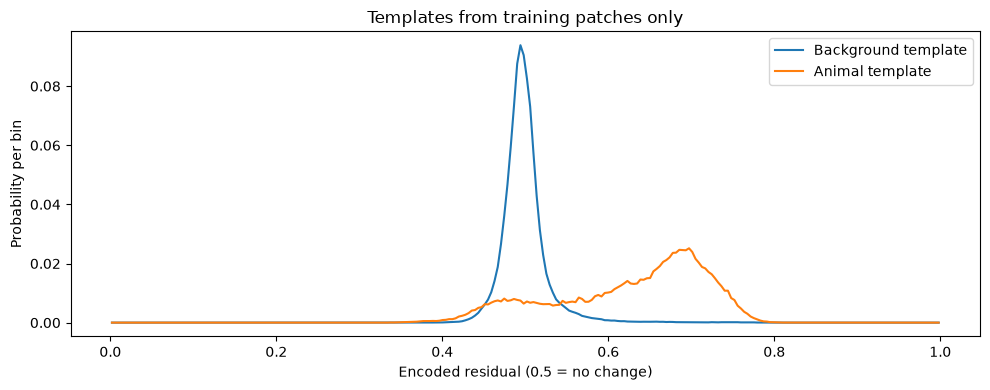

Templates fitted from 535 animal patches and 1440 background patches in 60 old training photos.


In [5]:
# Cell 05 — Fit templates from the old training data only
# Output: Training-only templates and their histograms.
# Check the old training sequence is animal-only. No test labels are read here.
training_gt=pd.read_csv('annotations/training_sequence.csv',header=None)
assert (training_gt[6]==0).all()
features=[];labels=[]
for row in training_frames.itertuples():
    p=Path('training_images')/row.filename
    assert hashlib.sha256(p.read_bytes()).hexdigest()==row.sha256
    a=np.asarray(Image.open(p).convert('L'),dtype=float)/255
    _,_,r=process(a)
    for sample in training_patches[training_patches.frame==row.frame].itertuples():
        features.append(hist(center_patch(r,int(sample.cx),int(sample.cy))))
        labels.append(int(sample.label))
# Use the same float32 feature storage as the earlier 100-image experiment.
X=np.asarray(features,dtype=np.float32);labels=np.asarray(labels)
TEMPLATES={c:X[labels==c].mean(axis=0) for c in [0,1]}
assert (labels==1).sum()==535 and (labels==0).sum()==1440
assert all(np.isclose(t.sum(),1) for t in TEMPLATES.values())
np.savez(OUT/'training_templates.npz',background=TEMPLATES[0],animal=TEMPLATES[1])
fig,ax=plt.subplots(figsize=(10,4))
ax.plot(CENTERS,TEMPLATES[0],label='Background template',color='tab:blue')
ax.plot(CENTERS,TEMPLATES[1],label='Animal template',color='tab:orange')
ax.set(xlabel='Encoded residual (0.5 = no change)',ylabel='Probability per bin',title='Templates from training patches only');ax.legend();savefig('training_templates')
print('Templates fitted from 535 animal patches and 1440 background patches in 60 old training photos.')


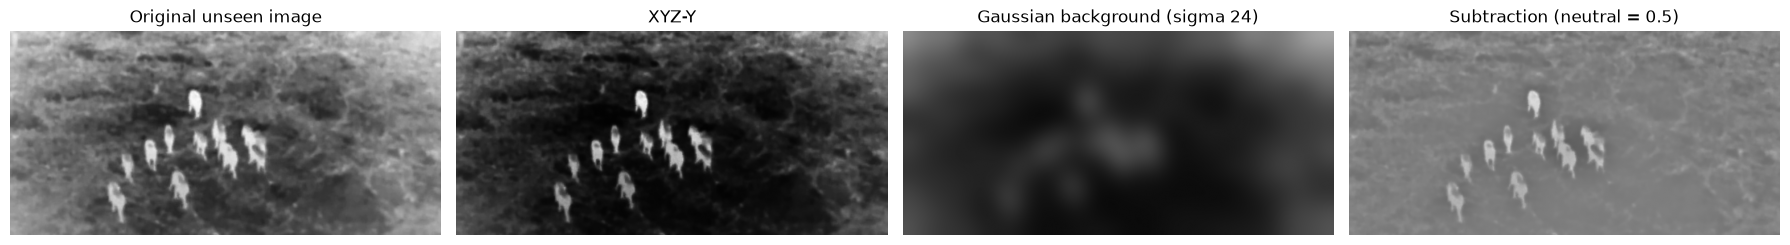

Image size: (398, 840) | Test GT has not been loaded.


In [6]:
# Cell 06 — Read the new image without its GT
# Output: Original and all processing stages together; no annotation-based crop.
manifest=json.loads(Path('input_manifest.json').read_text())
OUT=Path('results')/'positive_animal_sequence';OUT.mkdir(parents=True,exist_ok=True)
assert manifest['sequence']!='0000000367_0000000000'
assert manifest['sha256'] not in set(training_frames.sha256)
INPUT_PATH=Path('input')/manifest['filename']
assert hashlib.sha256(INPUT_PATH.read_bytes()).hexdigest()==manifest['sha256']
original=np.asarray(Image.open(INPUT_PATH).convert('L'),dtype=float)/255
Y,B,processed=process(original)
assert np.isfinite(processed).all() and processed.shape==original.shape
fig,axes=plt.subplots(1,4,figsize=(18,4))
for ax,a,title in zip(axes,[original,Y,B,processed],['Original unseen image','XYZ-Y','Gaussian background (sigma 24)','Subtraction (neutral = 0.5)']):
    ax.imshow(a,cmap='gray',vmin=0,vmax=1);ax.set_title(title);ax.axis('off')
savefig('new_image_pipeline')
print('Image size:',original.shape,'| Test GT has not been loaded.')


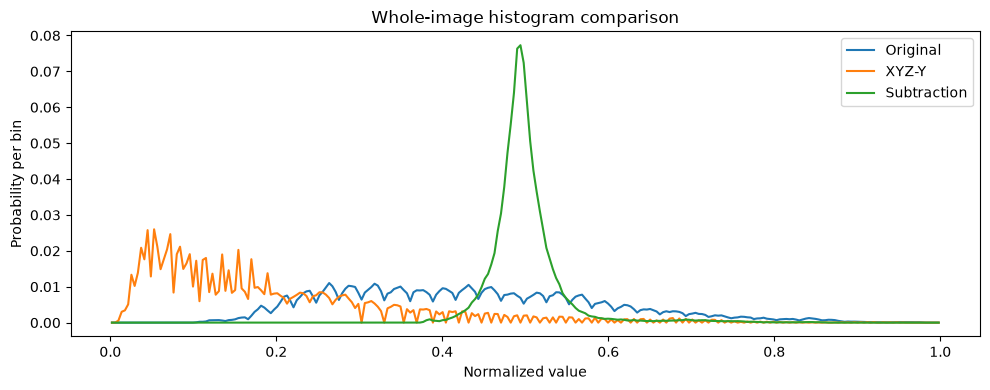

Original is brightness. Subtraction is encoded change; 0.5 means no change.


In [7]:
# Cell 07 — Original and processed histograms
# Output: Whole-image histogram overlays.
fig,ax=plt.subplots(figsize=(10,4))
for a,name in [(original,'Original'),(Y,'XYZ-Y'),(processed,'Subtraction')]:ax.plot(CENTERS,hist(a),label=name)
ax.set(xlabel='Normalized value',ylabel='Probability per bin',title='Whole-image histogram comparison');ax.legend();savefig('new_image_histograms')
print('Original is brightness. Subtraction is encoded change; 0.5 means no change.')


In [8]:
# Cell 08 — Scan every part of the image
# Output: Predictions for all windows, including background clutter and image edges.
def scan_full_image(a,templates):
    # Only image pixels and TRAIN templates enter this function. No GT argument.
    _,_,r=process(a);h,w=a.shape
    xs=starts(w,CFG['window'],CFG['stride']);ys=starts(h,CFG['window'],CFG['stride'])
    rows=[];positive=np.zeros((len(ys),len(xs)),bool)
    score_sum=np.zeros(a.shape,float);coverage=np.zeros(a.shape,np.int32)
    for iy,y in enumerate(ys):
        for ix,x in enumerate(xs):
            p=hist(r[y:y+16,x:x+16]).astype(np.float32)
            d_bg=float(np.abs(p-templates[0]).sum());d_animal=float(np.abs(p-templates[1]).sum())
            score=d_bg-d_animal;pred=int(d_animal<d_bg)
            positive[iy,ix]=bool(pred)
            rows.append(dict(grid_y=iy,grid_x=ix,x=x,y=y,width=16,height=16,
                             distance_animal=d_animal,distance_background=d_bg,score=score,prediction=pred))
            score_sum[y:y+16,x:x+16]+=score;coverage[y:y+16,x:x+16]+=1
    assert (coverage>0).all()
    return pd.DataFrame(rows),positive,score_sum/coverage,coverage
scan,positive_grid,score_map,coverage=scan_full_image(original,TEMPLATES)
table(scan,'all_window_predictions')
np.savez_compressed(OUT/'full_image_maps.npz',score=score_map,coverage=coverage,positive_grid=positive_grid)
print('Windows scanned:',len(scan),'| positive windows:',int(scan.prediction.sum()))
print('Image pixel coverage:',float((coverage>0).mean()),'| GT is still not loaded.')


,grid_y,grid_x,x,y,width,height,distance_animal,distance_background,score,prediction
0,0,0,0,0,16,16,1.399022,1.566146,0.167124,1
1,0,1,8,0,16,16,1.369509,1.054264,-0.315245,0
2,0,2,16,0,16,16,1.675350,0.581619,-1.093732,0
3,0,3,24,0,16,16,1.667538,0.701085,-0.966453,0
4,0,4,32,0,16,16,1.646466,1.038108,-0.608359,0
...,...,...,...,...,...,...,...,...,...,...
5091,48,99,792,382,16,16,1.856060,0.781293,-1.074767,0
5092,48,100,800,382,16,16,1.806746,0.511963,-1.294784,0
5093,48,101,808,382,16,16,1.794159,0.678543,-1.115616,0
5094,48,102,816,382,16,16,1.740756,0.877116,-0.863640,0


Windows scanned: 5096 | positive windows: 375
Image pixel coverage: 1.0 | GT is still not loaded.


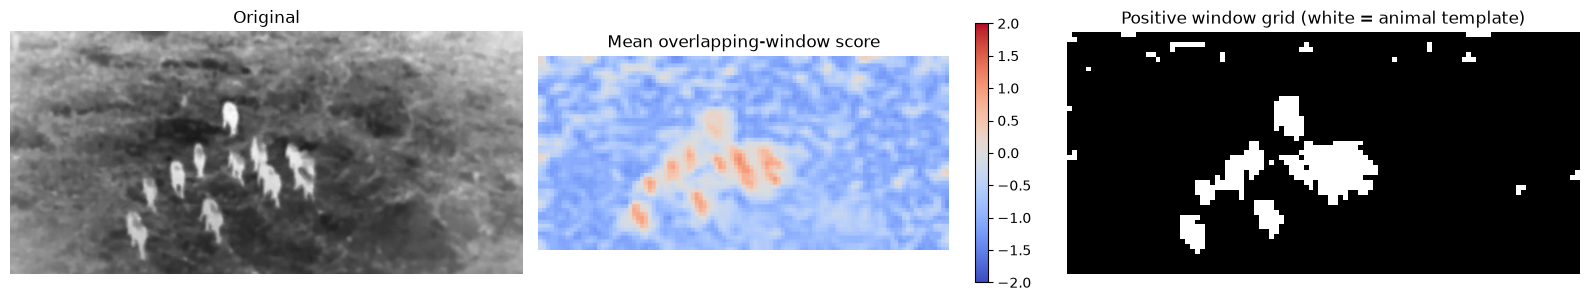

Positive score means closer to the animal template. It is not an animal probability.


In [9]:
# Cell 09 — Whole-image score heatmap
# Output: Full-image scores and positive scan locations, without GT.
fig,axes=plt.subplots(1,3,figsize=(16,4))
axes[0].imshow(original,cmap='gray',vmin=0,vmax=1);axes[0].set_title('Original')
im=axes[1].imshow(score_map,cmap='coolwarm',vmin=-2,vmax=2);axes[1].set_title('Mean overlapping-window score');fig.colorbar(im,ax=axes[1],shrink=.7)
axes[2].imshow(positive_grid,cmap='gray',vmin=0,vmax=1,interpolation='nearest');axes[2].set_title('Positive window grid (white = animal template)')
for ax in axes:ax.axis('off')
savefig('whole_image_score_maps')
print('Positive score means closer to the animal template. It is not an animal probability.')


In [10]:
# Cell 10 — Group nearby positive windows into candidate boxes
# Output: A saved yes/no decision and candidate regions, made before reading test labels.
# Neighboring positive windows form one candidate. Nearby animals may merge.
# Keep even a one-window component. Do not tune a size filter using this new image.
components,count=ndi.label(positive_grid,structure=np.ones((3,3),dtype=int))
boxes=[]
for component in range(1,count+1):
    iy,ix=np.where(components==component)
    indices=np.ravel_multi_index((iy,ix),positive_grid.shape)
    members=scan.iloc[indices]
    if len(members)<CFG['minimum_positive_windows']:continue
    x0=int(members.x.min());y0=int(members.y.min())
    x1=int((members.x+members.width).max());y1=int((members.y+members.height).max())
    boxes.append(dict(candidate_id=len(boxes)+1,x=x0,y=y0,width=x1-x0,height=y1-y0,
                      positive_windows=len(members),mean_score=float(members.score.mean()),max_score=float(members.score.max())))
candidates=pd.DataFrame(boxes,columns=['candidate_id','x','y','width','height','positive_windows','mean_score','max_score'])
ANIMAL_PRESENT=not candidates.empty
table(candidates,'candidate_boxes_before_gt')
prediction=dict(image=manifest['filename'],animal_present=ANIMAL_PRESENT,candidate_regions=len(candidates),
                positive_windows=int(scan.prediction.sum()),total_windows=len(scan),pixel_coverage=float((coverage>0).mean()),
                pipeline='XYZ-Y -> Gaussian sigma 24 -> Subtraction -> 16x16 histogram -> L1',
                stride=CFG['stride'],gt_used_for_prediction=False,postprocessing='8-connected positive window components; no size filter')
(OUT/'prediction_before_gt.json').write_text(json.dumps(prediction,indent=2))
PREDICTION_HASH=hashlib.sha256((OUT/'prediction_before_gt.json').read_bytes()).hexdigest()
print('ANIMAL DETECTED' if ANIMAL_PRESENT else 'NO ANIMAL DETECTED')
print('Candidate regions:',len(candidates),'| This is not an animal count.')


,candidate_id,x,y,width,height,positive_windows,mean_score,max_score
0,1,0,0,24,24,3,0.120361,0.175702
1,2,88,0,32,16,3,0.143488,0.267012
2,3,648,0,48,16,5,0.205227,0.359705
3,4,168,16,64,24,8,0.101617,0.175956
4,5,376,16,32,24,4,0.137227,0.316969
5,6,584,16,16,24,2,0.169472,0.317945
6,7,128,32,32,24,3,0.025877,0.033975
7,8,248,32,16,24,2,0.114361,0.141351
8,9,640,32,32,24,4,0.157778,0.332504
9,10,528,40,16,16,1,0.052841,0.052841


ANIMAL DETECTED
Candidate regions: 21 | This is not an animal count.


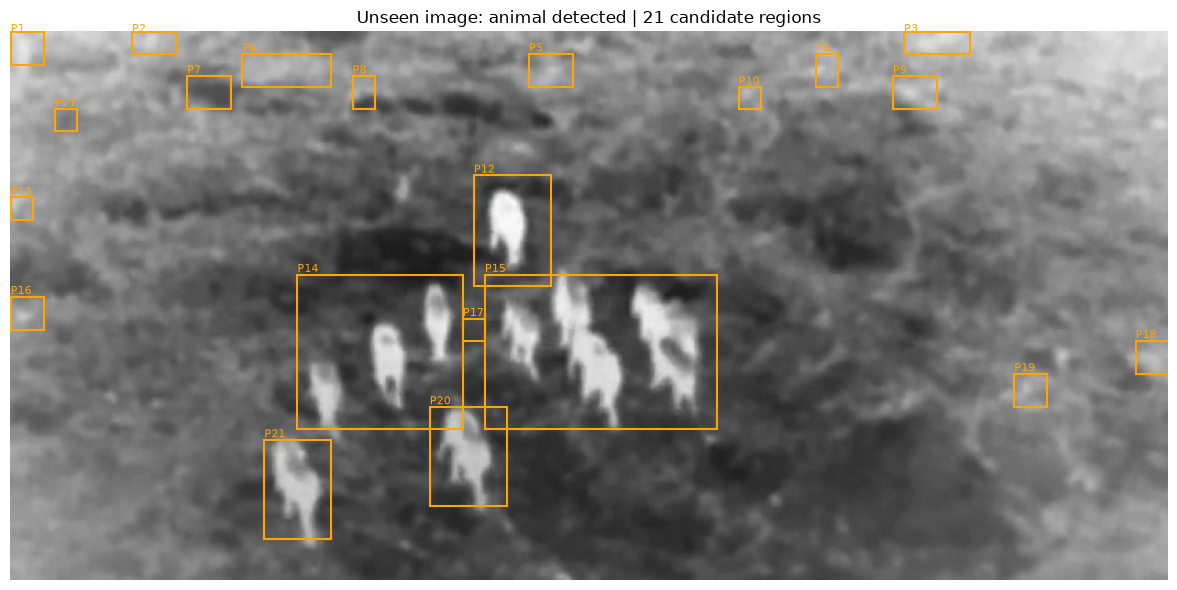

Orange boxes here are PREDICTIONS, unlike the orange GT ROI boxes in the earlier notebook.


In [11]:
# Cell 11 — Show the detector output before GT
# Output: The actual full-image detector output; no GT involved.
fig,ax=plt.subplots(figsize=(13,6));ax.imshow(original,cmap='gray',vmin=0,vmax=1)
for b in candidates.itertuples():
    ax.add_patch(Rectangle((b.x,b.y),b.width,b.height,fill=False,edgecolor='orange',lw=1.5))
    ax.text(b.x,max(0,b.y-2),f'P{b.candidate_id}',color='orange',fontsize=8)
ax.set_title(f'Unseen image: {"animal detected" if ANIMAL_PRESENT else "no animal detected"} | {len(candidates)} candidate regions')
ax.axis('off');savefig('prediction_before_gt')
print('Orange boxes here are PREDICTIONS, unlike the orange GT ROI boxes in the earlier notebook.')


In [12]:
# Cell 12 — Now load GT only for evaluation
# Output: Actual test annotations loaded after the saved prediction.
# Prediction is already saved. GT cannot move the boxes or change the yes/no answer.
assert hashlib.sha256((OUT/'prediction_before_gt.json').read_bytes()).hexdigest()==PREDICTION_HASH
names=['frame','track_id','x','y','width','height','class_id','species','occlusion','noise']
all_gt=pd.read_csv(Path('annotations')/(manifest['sequence']+'.csv'),header=None,names=names)
frame_gt=all_gt[(all_gt.frame==int(manifest['frame']))&(all_gt.width>0)&(all_gt.height>0)].copy()
table(frame_gt,'all_class_gt_after_prediction')
# Animal targets only. Human boxes are not animal ground truth.
gt=frame_gt[frame_gt.class_id==0].copy()
human_gt=frame_gt[frame_gt.class_id==1].copy()
# Clip animal boxes to the real image bounds. Keep species, occlusion and noise flags.
H,W=original.shape
gt['x1']=np.clip(gt.x+gt.width,0,W);gt['y1']=np.clip(gt.y+gt.height,0,H)
gt['x']=np.clip(gt.x,0,W);gt['y']=np.clip(gt.y,0,H)
gt=gt[(gt.x1>gt.x)&(gt.y1>gt.y)].copy();gt['width']=gt.x1-gt.x;gt['height']=gt.y1-gt.y
gt=gt.reset_index(drop=True)
table(gt,'test_gt_after_prediction')
print('Dataset animal boxes:',len(gt),'| Human boxes:',len(human_gt))
print('These are box labels, not exact animal-pixel masks. No pixel-segmentation score is claimed.')


,frame,track_id,x,y,width,height,class_id,species,occlusion,noise
715,71,1,299,178,25,72,0,1,0,0
716,71,4,461,221,52,67,0,1,0,0
717,71,5,346,103,42,77,0,1,0,0
718,71,6,356,194,34,58,0,1,0,0
719,71,7,212,232,33,65,0,1,0,0
720,71,8,404,211,49,78,0,1,0,0
721,71,9,256,203,35,73,0,1,0,0
722,71,10,183,293,50,82,0,1,0,0
723,71,11,309,271,51,79,0,1,0,0


,frame,track_id,x,y,width,height,class_id,species,occlusion,noise,x1,y1
0,71,1,299,178,25,72,0,1,0,0,324,250
1,71,4,461,221,52,67,0,1,0,0,513,288
2,71,5,346,103,42,77,0,1,0,0,388,180
3,71,6,356,194,34,58,0,1,0,0,390,252
4,71,7,212,232,33,65,0,1,0,0,245,297
5,71,8,404,211,49,78,0,1,0,0,453,289
6,71,9,256,203,35,73,0,1,0,0,291,276
7,71,10,183,293,50,82,0,1,0,0,233,375
8,71,11,309,271,51,79,0,1,0,0,360,350


Dataset animal boxes: 9 | Human boxes: 0
These are box labels, not exact animal-pixel masks. No pixel-segmentation score is claimed.


In [13]:
# Cell 13 — Object matching formula and rules
# Output: Separate object evaluation formulas; fixed IoU=0.5, not tuned on this image.
display(Math(r'IoU(P,G)=\frac{|P\cap G|}{|P\cup G|},\qquad\mathrm{match\ only\ if}\ IoU\geq0.5'))
display(Math(r'TP=\#\mathrm{one\!:\!one\ matches},\quad FP=\#P-TP,\quad FN=\#G-TP'))
display(Math(r'Precision=TP/(TP+FP),\quad Recall=TP/(TP+FN),\quad F_1=2TP/(2TP+FP+FN)'))
print('Use one-to-one matching. A big box around a whole herd cannot count as many correct animal detections.')
print('There is no natural object-level TN count, so object detection accuracy is not reported.')


<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

Use one-to-one matching. A big box around a whole herd cannot count as many correct animal detections.
There is no natural object-level TN count, so object detection accuracy is not reported.


In [14]:
# Cell 14 — Evaluate candidate boxes and image-level presence
# Output: Image-level correctness plus one-to-one object TP/FP/FN, precision, recall and F1.
def box_iou(a,b):
    ax0,ay0,aw,ah=a;bx0,by0,bw,bh=b
    area=max(0,min(ax0+aw,bx0+bw)-max(ax0,bx0))*max(0,min(ay0+ah,by0+bh)-max(ay0,by0))
    return area/(aw*ah+bw*bh-area+EPS)
P=candidates[['x','y','width','height']].to_numpy(float);G=gt[['x','y','width','height']].to_numpy(float)
ious=np.array([[box_iou(p,g) for g in G] for p in P],dtype=float).reshape(len(P),len(G))
matched=[]
if len(P) and len(G):
    valid=ious>=CFG['object_iou']
    # First maximize the count of valid matches, then their total IoU.
    weights=np.where(valid,min(len(P),len(G))+1+ious,0)
    pi,gi=linear_sum_assignment(weights,maximize=True)
    matched=[(int(i),int(j),float(ious[i,j])) for i,j in zip(pi,gi) if valid[i,j]]
TP=len(matched);FP=len(P)-TP;FN=len(G)-TP
precision=TP/len(P) if len(P) else np.nan
recall=TP/len(G) if len(G) else np.nan
f1=2*TP/(2*TP+FP+FN) if 2*TP+FP+FN else np.nan
object_result=pd.DataFrame([dict(iou_cutoff=CFG['object_iou'],predicted_regions=len(P),gt_animals=len(G),TP=TP,FP=FP,FN=FN,
                                  precision=precision,recall=recall,f1=f1)])
table(object_result,'object_detection_evaluation')
match_table=pd.DataFrame([dict(candidate_id=int(candidates.iloc[i].candidate_id),track_id=int(gt.iloc[j].track_id),iou=v) for i,j,v in matched],columns=['candidate_id','track_id','iou'])
table(match_table,'one_to_one_matches')
presence=pd.DataFrame([dict(predicted_animal_present=ANIMAL_PRESENT,gt_animal_present=bool(len(gt)),
                            correct=ANIMAL_PRESENT==bool(len(gt)),images_tested=1)])
table(presence,'image_presence_evaluation')
print('The yes/no row is one case result, not a 100% accuracy claim for unseen images.')


,iou_cutoff,predicted_regions,gt_animals,TP,FP,FN,precision,recall,f1
0,0.5,21,9,3,18,6,0.142857,0.333333,0.2


,candidate_id,track_id,iou
0,12,5,0.705882
1,20,11,0.836637
2,21,10,0.842927


,predicted_animal_present,gt_animal_present,correct,images_tested
0,True,True,True,1


The yes/no row is one case result, not a 100% accuracy claim for unseen images.


In [15]:
# Cell 15 — Evaluate all scan windows, not selected GT-center patches
# Output: All-window confusion counts and metrics, with ambiguous windows counted explicitly.
# Positive label: the window center is inside at least one dataset animal box.
# Negative label: the whole window misses every animal box.
# Border overlap with the center outside is ambiguous; exclude it and report how many.
# This is a box-based proxy, not pixel segmentation truth.
scan_eval=scan.copy();labels=[]
for row in scan.itertuples():
    cx=row.x+8;cy=row.y+8
    inside=any(x<=cx<x+w and y<=cy<y+h for x,y,w,h in G)
    overlaps=any(min(row.x+16,x+w)>max(row.x,x) and min(row.y+16,y+h)>max(row.y,y) for x,y,w,h in G)
    labels.append(1 if inside else -1 if overlaps else 0)
scan_eval['gt_label']=labels;valid=scan_eval.gt_label>=0
v=scan_eval[valid];yy=v.gt_label.to_numpy();pp=v.prediction.to_numpy()
tp=int(((yy==1)&(pp==1)).sum());fp=int(((yy==0)&(pp==1)).sum());tn=int(((yy==0)&(pp==0)).sum());fn=int(((yy==1)&(pp==0)).sum())
window_result=pd.DataFrame([dict(total_windows=len(scan),scored_windows=len(v),ambiguous_windows=int((~valid).sum()),
    TP=tp,FP=fp,TN=tn,FN=fn,accuracy=accuracy_score(yy,pp) if len(v) else np.nan,
    balanced_accuracy=balanced_accuracy_score(yy,pp) if len(np.unique(yy))==2 else np.nan,
    precision=tp/(tp+fp) if tp+fp else np.nan,recall=tp/(tp+fn) if tp+fn else np.nan,
    f1=2*tp/(2*tp+fp+fn) if 2*tp+fp+fn else np.nan,
    auc=roc_auc_score(yy,v.score) if len(np.unique(yy))==2 else np.nan)])
table(window_result,'full_scan_window_evaluation');table(scan_eval,'all_windows_with_gt_after_prediction')
print('Overlapping windows are correlated. Do not compare this accuracy directly to the earlier selected-patch accuracy.')


,total_windows,scored_windows,ambiguous_windows,TP,FP,TN,FN,accuracy,balanced_accuracy,precision,recall,f1,auc
0,5096,4849,247,247,79,4341,182,0.946174,0.778942,0.757669,0.575758,0.654305,0.929854


,grid_y,grid_x,x,y,width,height,distance_animal,distance_background,score,prediction,gt_label
0,0,0,0,0,16,16,1.399022,1.566146,0.167124,1,0
1,0,1,8,0,16,16,1.369509,1.054264,-0.315245,0,0
2,0,2,16,0,16,16,1.675350,0.581619,-1.093732,0,0
3,0,3,24,0,16,16,1.667538,0.701085,-0.966453,0,0
4,0,4,32,0,16,16,1.646466,1.038108,-0.608359,0,0
...,...,...,...,...,...,...,...,...,...,...,...
5091,48,99,792,382,16,16,1.856060,0.781293,-1.074767,0,0
5092,48,100,800,382,16,16,1.806746,0.511963,-1.294784,0,0
5093,48,101,808,382,16,16,1.794159,0.678543,-1.115616,0,0
5094,48,102,816,382,16,16,1.740756,0.877116,-0.863640,0,0


Overlapping windows are correlated. Do not compare this accuracy directly to the earlier selected-patch accuracy.


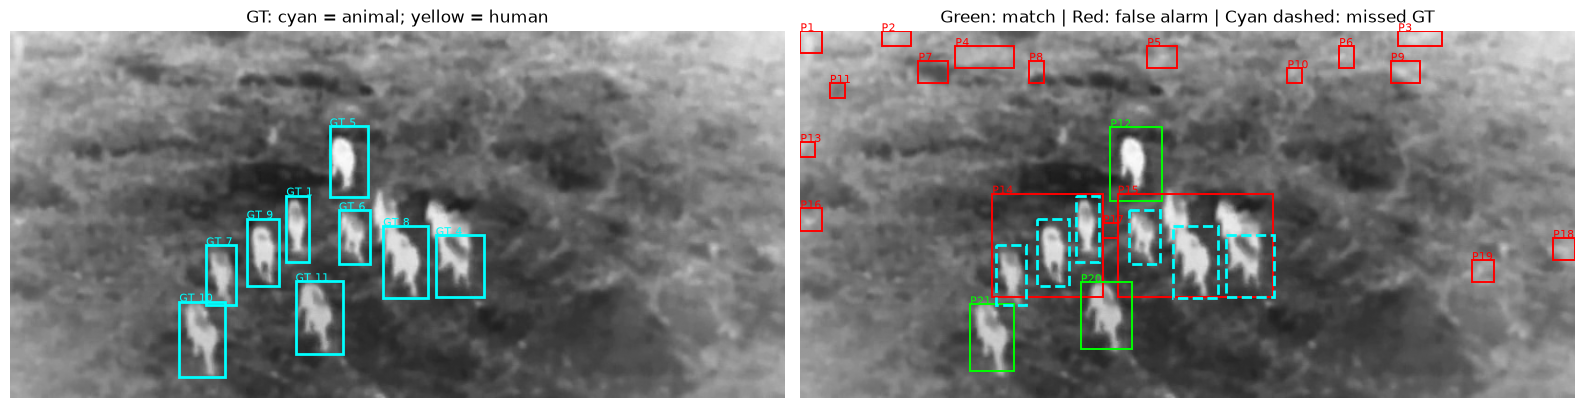

In [16]:
# Cell 16 — Show correct matches, false alarms and missed animals
# Output: Prediction-vs-GT overlay, including every false alarm and missed animal.
matched_p={i for i,j,v in matched};matched_g={j for i,j,v in matched}
fig,axes=plt.subplots(1,2,figsize=(16,5))
for ax in axes:ax.imshow(original,cmap='gray',vmin=0,vmax=1);ax.axis('off')
for j,b in gt.iterrows():
    axes[0].add_patch(Rectangle((b.x,b.y),b.width,b.height,fill=False,color='cyan',lw=2))
    axes[0].text(b.x,b.y,f'GT {int(b.track_id)}',color='cyan',fontsize=8)
for i,b in candidates.iterrows():
    color_now='lime' if i in matched_p else 'red'
    axes[1].add_patch(Rectangle((b.x,b.y),b.width,b.height,fill=False,color=color_now,lw=1.4))
    axes[1].text(b.x,b.y,f'P{int(b.candidate_id)}',color=color_now,fontsize=8)
for j,b in gt.iterrows():
    if j not in matched_g:axes[1].add_patch(Rectangle((b.x,b.y),b.width,b.height,fill=False,color='cyan',lw=2,linestyle='--'))
for b in human_gt.itertuples():
    axes[0].add_patch(Rectangle((b.x,b.y),b.width,b.height,fill=False,color='yellow',lw=1.5))
axes[0].set_title('GT: cyan = animal; yellow = human')
axes[1].set_title('Green: match | Red: false alarm | Cyan dashed: missed GT')
savefig('full_image_detection_errors')


In [17]:
# Cell 17 — Final full-image result and checks
# Output: Honest final summary, saved predictions and numerical integrity checks.
assert prediction['gt_used_for_prediction'] is False and (coverage>0).all()
assert TP+FP==len(candidates) and TP+FN==len(gt)
assert len({i for i,j,v in matched})==len(matched)==len({j for i,j,v in matched})
assert hashlib.sha256((OUT/'prediction_before_gt.json').read_bytes()).hexdigest()==PREDICTION_HASH
summary=dict(input=manifest,pipeline=prediction['pipeline'],settings=CFG,training_frames=60,training_animal_patches=535,
             training_background_patches=1440,prediction=prediction,object_evaluation=object_result.iloc[0].to_dict(),
             window_evaluation=window_result.iloc[0].to_dict(),presence_correct=bool(presence.iloc[0]['correct']),
             limitations=['Two hand-specified sequence cases; not a representative benchmark','GT boxes are not pixel masks','Background assumes complete GT',
                          'Adjacent positive windows can merge several animals','No test-image tuning or GT-guided proposals'])
def clean_json(v):
    if isinstance(v,dict):return {k:clean_json(x) for k,x in v.items()}
    if isinstance(v,list):return [clean_json(x) for x in v]
    if hasattr(v,'item'):v=v.item()
    if isinstance(v,float) and not np.isfinite(v):return None
    return v
summary=clean_json(summary)
(OUT/'FULL_IMAGE_SUMMARY.json').write_text(json.dumps(summary,indent=2,allow_nan=False))
print('Prediction:', 'animal detected' if ANIMAL_PRESENT else 'no animal detected')
print(f'Object results at IoU 0.5: TP={TP}, FP={FP}, FN={FN}')
print('Read image presence, object localization and full-scan window scores as THREE different results.')
print('This test may be harder than the earlier selected-patch test. Report failures too.')
print('All files saved in:',OUT.resolve())


Prediction: animal detected
Object results at IoU 0.5: TP=3, FP=18, FN=6
Read image presence, object localization and full-scan window scores as THREE different results.
This test may be harder than the earlier selected-patch test. Report failures too.
All files saved in: /Users/yingying/.codex/.chatgpt-projects/g-p-6a9853e50250819194465d3e0ed1452b/output/Wildlife_Full_Image_Evaluation/results/positive_animal_sequence


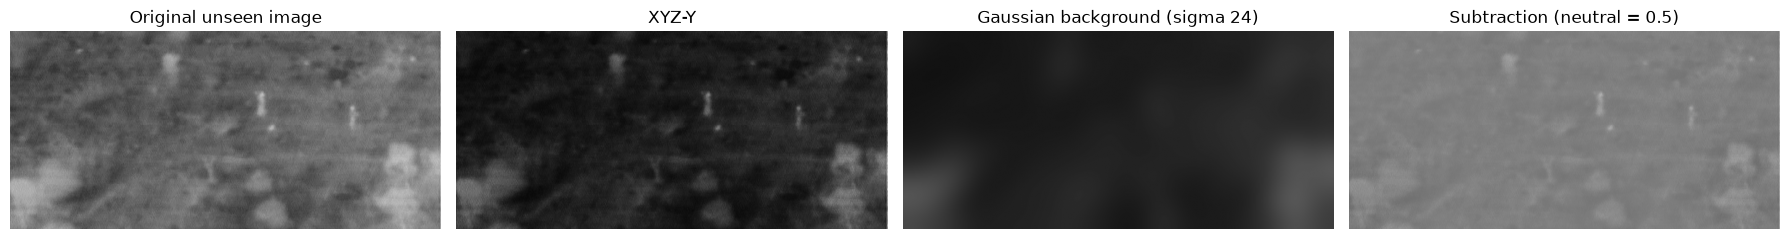

Image size: (321, 700) | Test GT has not been loaded.


In [18]:
# Cell 18 — Read the new image without its GT
# Output: Original and all processing stages together; no annotation-based crop.
manifest=json.loads(Path('negative_manifest.json').read_text())
OUT=Path('results')/'negative_human_sequence';OUT.mkdir(parents=True,exist_ok=True)
assert manifest['sequence']!='0000000367_0000000000'
assert manifest['sha256'] not in set(training_frames.sha256)
INPUT_PATH=Path('input')/manifest['filename']
assert hashlib.sha256(INPUT_PATH.read_bytes()).hexdigest()==manifest['sha256']
original=np.asarray(Image.open(INPUT_PATH).convert('L'),dtype=float)/255
Y,B,processed=process(original)
assert np.isfinite(processed).all() and processed.shape==original.shape
fig,axes=plt.subplots(1,4,figsize=(18,4))
for ax,a,title in zip(axes,[original,Y,B,processed],['Original unseen image','XYZ-Y','Gaussian background (sigma 24)','Subtraction (neutral = 0.5)']):
    ax.imshow(a,cmap='gray',vmin=0,vmax=1);ax.set_title(title);ax.axis('off')
savefig('new_image_pipeline')
print('Image size:',original.shape,'| Test GT has not been loaded.')


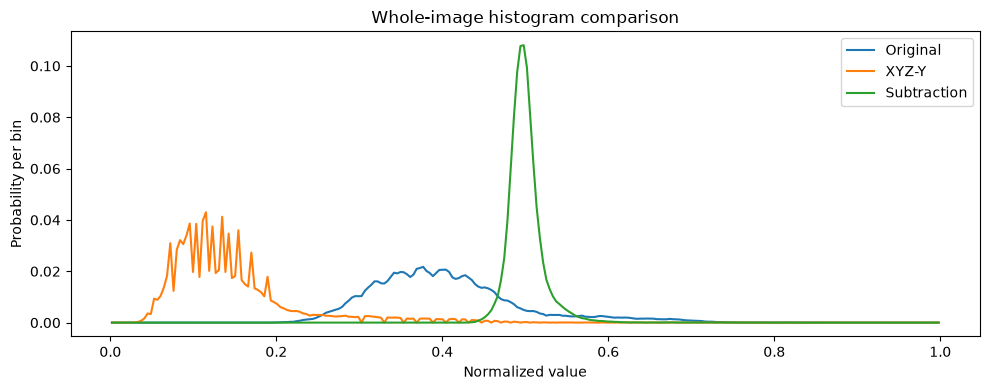

Original is brightness. Subtraction is encoded change; 0.5 means no change.


In [19]:
# Cell 19 — Original and processed histograms
# Output: Whole-image histogram overlays.
fig,ax=plt.subplots(figsize=(10,4))
for a,name in [(original,'Original'),(Y,'XYZ-Y'),(processed,'Subtraction')]:ax.plot(CENTERS,hist(a),label=name)
ax.set(xlabel='Normalized value',ylabel='Probability per bin',title='Whole-image histogram comparison');ax.legend();savefig('new_image_histograms')
print('Original is brightness. Subtraction is encoded change; 0.5 means no change.')


In [20]:
# Cell 20 — Scan every part of the image
# Output: Predictions for all windows, including background clutter and image edges.
def scan_full_image(a,templates):
    # Only image pixels and TRAIN templates enter this function. No GT argument.
    _,_,r=process(a);h,w=a.shape
    xs=starts(w,CFG['window'],CFG['stride']);ys=starts(h,CFG['window'],CFG['stride'])
    rows=[];positive=np.zeros((len(ys),len(xs)),bool)
    score_sum=np.zeros(a.shape,float);coverage=np.zeros(a.shape,np.int32)
    for iy,y in enumerate(ys):
        for ix,x in enumerate(xs):
            p=hist(r[y:y+16,x:x+16]).astype(np.float32)
            d_bg=float(np.abs(p-templates[0]).sum());d_animal=float(np.abs(p-templates[1]).sum())
            score=d_bg-d_animal;pred=int(d_animal<d_bg)
            positive[iy,ix]=bool(pred)
            rows.append(dict(grid_y=iy,grid_x=ix,x=x,y=y,width=16,height=16,
                             distance_animal=d_animal,distance_background=d_bg,score=score,prediction=pred))
            score_sum[y:y+16,x:x+16]+=score;coverage[y:y+16,x:x+16]+=1
    assert (coverage>0).all()
    return pd.DataFrame(rows),positive,score_sum/coverage,coverage
scan,positive_grid,score_map,coverage=scan_full_image(original,TEMPLATES)
table(scan,'all_window_predictions')
np.savez_compressed(OUT/'full_image_maps.npz',score=score_map,coverage=coverage,positive_grid=positive_grid)
print('Windows scanned:',len(scan),'| positive windows:',int(scan.prediction.sum()))
print('Image pixel coverage:',float((coverage>0).mean()),'| GT is still not loaded.')


,grid_y,grid_x,x,y,width,height,distance_animal,distance_background,score,prediction
0,0,0,0,0,16,16,1.824328,1.002018,-0.822310,0
1,0,1,8,0,16,16,1.839690,1.174338,-0.665352,0
2,0,2,16,0,16,16,1.859039,1.151703,-0.707336,0
3,0,3,24,0,16,16,1.896641,1.276703,-0.619938,0
4,0,4,32,0,16,16,1.845356,0.970801,-0.874556,0
...,...,...,...,...,...,...,...,...,...,...
3475,39,82,656,305,16,16,1.763128,0.648372,-1.114756,0
3476,39,83,664,305,16,16,1.773598,0.646881,-1.126718,0
3477,39,84,672,305,16,16,1.795415,0.674425,-1.120990,0
3478,39,85,680,305,16,16,1.755126,0.707205,-1.047921,0


Windows scanned: 3480 | positive windows: 39
Image pixel coverage: 1.0 | GT is still not loaded.


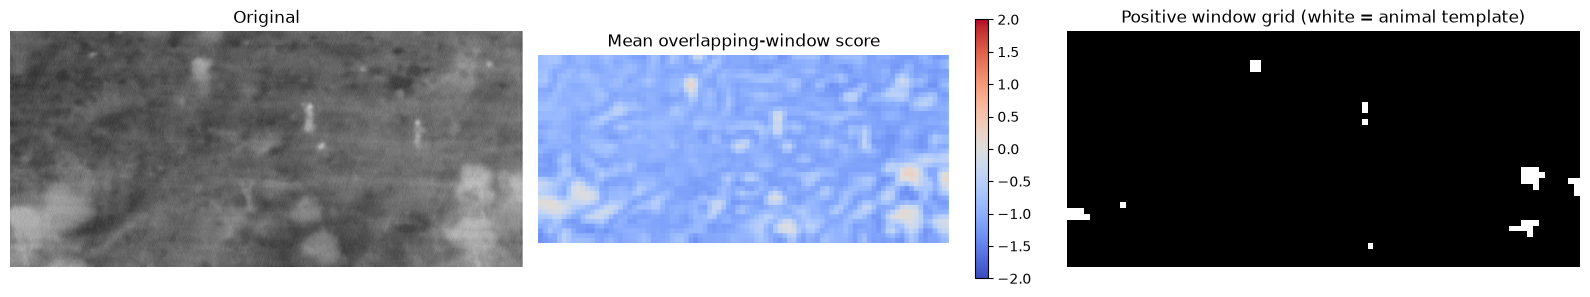

Positive score means closer to the animal template. It is not an animal probability.


In [21]:
# Cell 21 — Whole-image score heatmap
# Output: Full-image scores and positive scan locations, without GT.
fig,axes=plt.subplots(1,3,figsize=(16,4))
axes[0].imshow(original,cmap='gray',vmin=0,vmax=1);axes[0].set_title('Original')
im=axes[1].imshow(score_map,cmap='coolwarm',vmin=-2,vmax=2);axes[1].set_title('Mean overlapping-window score');fig.colorbar(im,ax=axes[1],shrink=.7)
axes[2].imshow(positive_grid,cmap='gray',vmin=0,vmax=1,interpolation='nearest');axes[2].set_title('Positive window grid (white = animal template)')
for ax in axes:ax.axis('off')
savefig('whole_image_score_maps')
print('Positive score means closer to the animal template. It is not an animal probability.')


In [22]:
# Cell 22 — Group nearby positive windows into candidate boxes
# Output: A saved yes/no decision and candidate regions, made before reading test labels.
# Neighboring positive windows form one candidate. Nearby animals may merge.
# Keep even a one-window component. Do not tune a size filter using this new image.
components,count=ndi.label(positive_grid,structure=np.ones((3,3),dtype=int))
boxes=[]
for component in range(1,count+1):
    iy,ix=np.where(components==component)
    indices=np.ravel_multi_index((iy,ix),positive_grid.shape)
    members=scan.iloc[indices]
    if len(members)<CFG['minimum_positive_windows']:continue
    x0=int(members.x.min());y0=int(members.y.min())
    x1=int((members.x+members.width).max());y1=int((members.y+members.height).max())
    boxes.append(dict(candidate_id=len(boxes)+1,x=x0,y=y0,width=x1-x0,height=y1-y0,
                      positive_windows=len(members),mean_score=float(members.score.mean()),max_score=float(members.score.max())))
candidates=pd.DataFrame(boxes,columns=['candidate_id','x','y','width','height','positive_windows','mean_score','max_score'])
ANIMAL_PRESENT=not candidates.empty
table(candidates,'candidate_boxes_before_gt')
prediction=dict(image=manifest['filename'],animal_present=ANIMAL_PRESENT,candidate_regions=len(candidates),
                positive_windows=int(scan.prediction.sum()),total_windows=len(scan),pixel_coverage=float((coverage>0).mean()),
                pipeline='XYZ-Y -> Gaussian sigma 24 -> Subtraction -> 16x16 histogram -> L1',
                stride=CFG['stride'],gt_used_for_prediction=False,postprocessing='8-connected positive window components; no size filter')
(OUT/'prediction_before_gt.json').write_text(json.dumps(prediction,indent=2))
PREDICTION_HASH=hashlib.sha256((OUT/'prediction_before_gt.json').read_bytes()).hexdigest()
print('ANIMAL DETECTED' if ANIMAL_PRESENT else 'NO ANIMAL DETECTED')
print('Candidate regions:',len(candidates),'| This is not an animal count.')


,candidate_id,x,y,width,height,positive_windows,mean_score,max_score
0,1,248,40,24,24,4,0.222362,0.288976
1,2,400,96,16,24,2,0.200651,0.264889
2,3,400,120,16,16,1,0.149600,0.149600
3,4,616,184,40,40,11,0.182252,0.292189
4,5,680,200,20,32,4,0.148533,0.293587
5,6,72,232,16,16,1,0.006754,0.006754
6,7,0,240,40,24,7,0.055088,0.085301
7,8,600,256,48,32,8,0.080180,0.164274
8,9,408,288,16,16,1,0.022700,0.022700


ANIMAL DETECTED
Candidate regions: 9 | This is not an animal count.


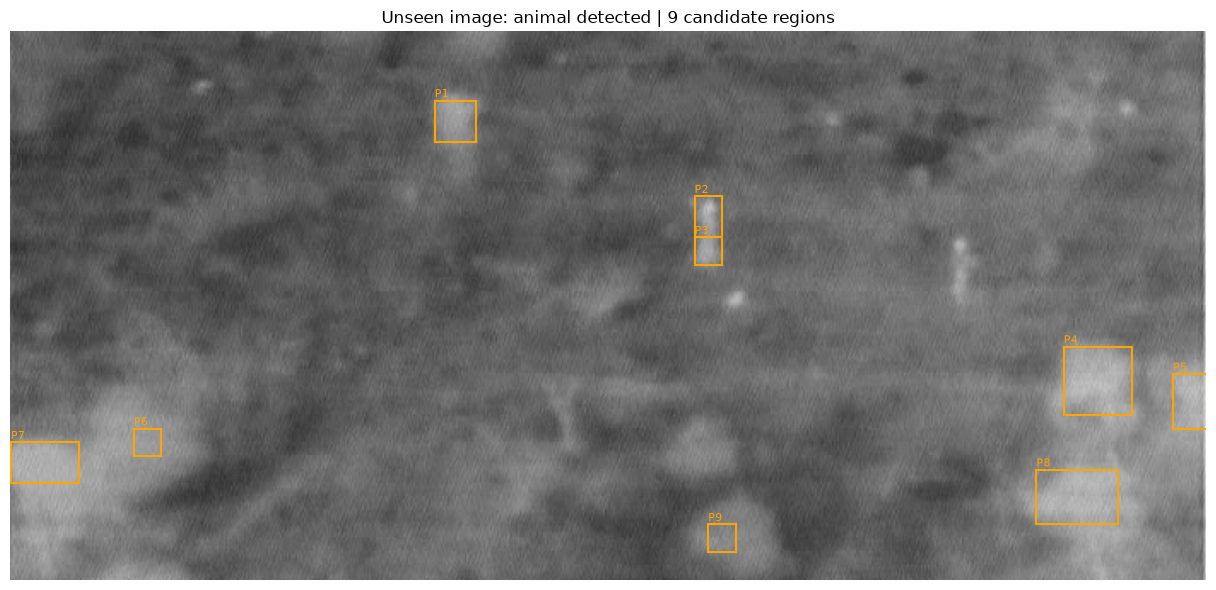

Orange boxes here are PREDICTIONS, unlike the orange GT ROI boxes in the earlier notebook.


In [23]:
# Cell 23 — Show the detector output before GT
# Output: The actual full-image detector output; no GT involved.
fig,ax=plt.subplots(figsize=(13,6));ax.imshow(original,cmap='gray',vmin=0,vmax=1)
for b in candidates.itertuples():
    ax.add_patch(Rectangle((b.x,b.y),b.width,b.height,fill=False,edgecolor='orange',lw=1.5))
    ax.text(b.x,max(0,b.y-2),f'P{b.candidate_id}',color='orange',fontsize=8)
ax.set_title(f'Unseen image: {"animal detected" if ANIMAL_PRESENT else "no animal detected"} | {len(candidates)} candidate regions')
ax.axis('off');savefig('prediction_before_gt')
print('Orange boxes here are PREDICTIONS, unlike the orange GT ROI boxes in the earlier notebook.')


In [24]:
# Cell 24 — Now load GT only for evaluation
# Output: Actual test annotations loaded after the saved prediction.
# Prediction is already saved. GT cannot move the boxes or change the yes/no answer.
assert hashlib.sha256((OUT/'prediction_before_gt.json').read_bytes()).hexdigest()==PREDICTION_HASH
names=['frame','track_id','x','y','width','height','class_id','species','occlusion','noise']
all_gt=pd.read_csv(Path('annotations')/(manifest['sequence']+'.csv'),header=None,names=names)
frame_gt=all_gt[(all_gt.frame==int(manifest['frame']))&(all_gt.width>0)&(all_gt.height>0)].copy()
table(frame_gt,'all_class_gt_after_prediction')
# Animal targets only. Human boxes are not animal ground truth.
gt=frame_gt[frame_gt.class_id==0].copy()
human_gt=frame_gt[frame_gt.class_id==1].copy()
# Clip animal boxes to the real image bounds. Keep species, occlusion and noise flags.
H,W=original.shape
gt['x1']=np.clip(gt.x+gt.width,0,W);gt['y1']=np.clip(gt.y+gt.height,0,H)
gt['x']=np.clip(gt.x,0,W);gt['y']=np.clip(gt.y,0,H)
gt=gt[(gt.x1>gt.x)&(gt.y1>gt.y)].copy();gt['width']=gt.x1-gt.x;gt['height']=gt.y1-gt.y
gt=gt.reset_index(drop=True)
table(gt,'test_gt_after_prediction')
print('Dataset animal boxes:',len(gt),'| Human boxes:',len(human_gt))
print('These are box labels, not exact animal-pixel masks. No pixel-segmentation score is claimed.')


,frame,track_id,x,y,width,height,class_id,species,occlusion,noise
2881,3978,1,548,118,22,44,1,0,0,0


,frame,track_id,x,y,width,height,class_id,species,occlusion,noise,x1,y1


Dataset animal boxes: 0 | Human boxes: 1
These are box labels, not exact animal-pixel masks. No pixel-segmentation score is claimed.


In [25]:
# Cell 25 — Object matching formula and rules
# Output: Separate object evaluation formulas; fixed IoU=0.5, not tuned on this image.
display(Math(r'IoU(P,G)=\frac{|P\cap G|}{|P\cup G|},\qquad\mathrm{match\ only\ if}\ IoU\geq0.5'))
display(Math(r'TP=\#\mathrm{one\!:\!one\ matches},\quad FP=\#P-TP,\quad FN=\#G-TP'))
display(Math(r'Precision=TP/(TP+FP),\quad Recall=TP/(TP+FN),\quad F_1=2TP/(2TP+FP+FN)'))
print('Use one-to-one matching. A big box around a whole herd cannot count as many correct animal detections.')
print('There is no natural object-level TN count, so object detection accuracy is not reported.')


<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

Use one-to-one matching. A big box around a whole herd cannot count as many correct animal detections.
There is no natural object-level TN count, so object detection accuracy is not reported.


In [26]:
# Cell 26 — Evaluate candidate boxes and image-level presence
# Output: Image-level correctness plus one-to-one object TP/FP/FN, precision, recall and F1.
def box_iou(a,b):
    ax0,ay0,aw,ah=a;bx0,by0,bw,bh=b
    area=max(0,min(ax0+aw,bx0+bw)-max(ax0,bx0))*max(0,min(ay0+ah,by0+bh)-max(ay0,by0))
    return area/(aw*ah+bw*bh-area+EPS)
P=candidates[['x','y','width','height']].to_numpy(float);G=gt[['x','y','width','height']].to_numpy(float)
ious=np.array([[box_iou(p,g) for g in G] for p in P],dtype=float).reshape(len(P),len(G))
matched=[]
if len(P) and len(G):
    valid=ious>=CFG['object_iou']
    # First maximize the count of valid matches, then their total IoU.
    weights=np.where(valid,min(len(P),len(G))+1+ious,0)
    pi,gi=linear_sum_assignment(weights,maximize=True)
    matched=[(int(i),int(j),float(ious[i,j])) for i,j in zip(pi,gi) if valid[i,j]]
TP=len(matched);FP=len(P)-TP;FN=len(G)-TP
precision=TP/len(P) if len(P) else np.nan
recall=TP/len(G) if len(G) else np.nan
f1=2*TP/(2*TP+FP+FN) if 2*TP+FP+FN else np.nan
object_result=pd.DataFrame([dict(iou_cutoff=CFG['object_iou'],predicted_regions=len(P),gt_animals=len(G),TP=TP,FP=FP,FN=FN,
                                  precision=precision,recall=recall,f1=f1)])
table(object_result,'object_detection_evaluation')
match_table=pd.DataFrame([dict(candidate_id=int(candidates.iloc[i].candidate_id),track_id=int(gt.iloc[j].track_id),iou=v) for i,j,v in matched],columns=['candidate_id','track_id','iou'])
table(match_table,'one_to_one_matches')
presence=pd.DataFrame([dict(predicted_animal_present=ANIMAL_PRESENT,gt_animal_present=bool(len(gt)),
                            correct=ANIMAL_PRESENT==bool(len(gt)),images_tested=1)])
table(presence,'image_presence_evaluation')
print('The yes/no row is one case result, not a 100% accuracy claim for unseen images.')


,iou_cutoff,predicted_regions,gt_animals,TP,FP,FN,precision,recall,f1
0,0.5,9,0,0,9,0,0.0,NaN,0.0


,candidate_id,track_id,iou


,predicted_animal_present,gt_animal_present,correct,images_tested
0,True,False,False,1


The yes/no row is one case result, not a 100% accuracy claim for unseen images.


In [27]:
# Cell 27 — Evaluate all scan windows, not selected GT-center patches
# Output: All-window confusion counts and metrics, with ambiguous windows counted explicitly.
# Positive label: the window center is inside at least one dataset animal box.
# Negative label: the whole window misses every animal box.
# Border overlap with the center outside is ambiguous; exclude it and report how many.
# This is a box-based proxy, not pixel segmentation truth.
scan_eval=scan.copy();labels=[]
for row in scan.itertuples():
    cx=row.x+8;cy=row.y+8
    inside=any(x<=cx<x+w and y<=cy<y+h for x,y,w,h in G)
    overlaps=any(min(row.x+16,x+w)>max(row.x,x) and min(row.y+16,y+h)>max(row.y,y) for x,y,w,h in G)
    labels.append(1 if inside else -1 if overlaps else 0)
scan_eval['gt_label']=labels;valid=scan_eval.gt_label>=0
v=scan_eval[valid];yy=v.gt_label.to_numpy();pp=v.prediction.to_numpy()
tp=int(((yy==1)&(pp==1)).sum());fp=int(((yy==0)&(pp==1)).sum());tn=int(((yy==0)&(pp==0)).sum());fn=int(((yy==1)&(pp==0)).sum())
window_result=pd.DataFrame([dict(total_windows=len(scan),scored_windows=len(v),ambiguous_windows=int((~valid).sum()),
    TP=tp,FP=fp,TN=tn,FN=fn,accuracy=accuracy_score(yy,pp) if len(v) else np.nan,
    balanced_accuracy=balanced_accuracy_score(yy,pp) if len(np.unique(yy))==2 else np.nan,
    precision=tp/(tp+fp) if tp+fp else np.nan,recall=tp/(tp+fn) if tp+fn else np.nan,
    f1=2*tp/(2*tp+fp+fn) if 2*tp+fp+fn else np.nan,
    auc=roc_auc_score(yy,v.score) if len(np.unique(yy))==2 else np.nan)])
table(window_result,'full_scan_window_evaluation');table(scan_eval,'all_windows_with_gt_after_prediction')
print('Overlapping windows are correlated. Do not compare this accuracy directly to the earlier selected-patch accuracy.')


,total_windows,scored_windows,ambiguous_windows,TP,FP,TN,FN,accuracy,balanced_accuracy,precision,recall,f1,auc
0,3480,3480,0,0,39,3441,0,0.988793,NaN,0.0,NaN,0.0,NaN


,grid_y,grid_x,x,y,width,height,distance_animal,distance_background,score,prediction,gt_label
0,0,0,0,0,16,16,1.824328,1.002018,-0.822310,0,0
1,0,1,8,0,16,16,1.839690,1.174338,-0.665352,0,0
2,0,2,16,0,16,16,1.859039,1.151703,-0.707336,0,0
3,0,3,24,0,16,16,1.896641,1.276703,-0.619938,0,0
4,0,4,32,0,16,16,1.845356,0.970801,-0.874556,0,0
...,...,...,...,...,...,...,...,...,...,...,...
3475,39,82,656,305,16,16,1.763128,0.648372,-1.114756,0,0
3476,39,83,664,305,16,16,1.773598,0.646881,-1.126718,0,0
3477,39,84,672,305,16,16,1.795415,0.674425,-1.120990,0,0
3478,39,85,680,305,16,16,1.755126,0.707205,-1.047921,0,0


Overlapping windows are correlated. Do not compare this accuracy directly to the earlier selected-patch accuracy.


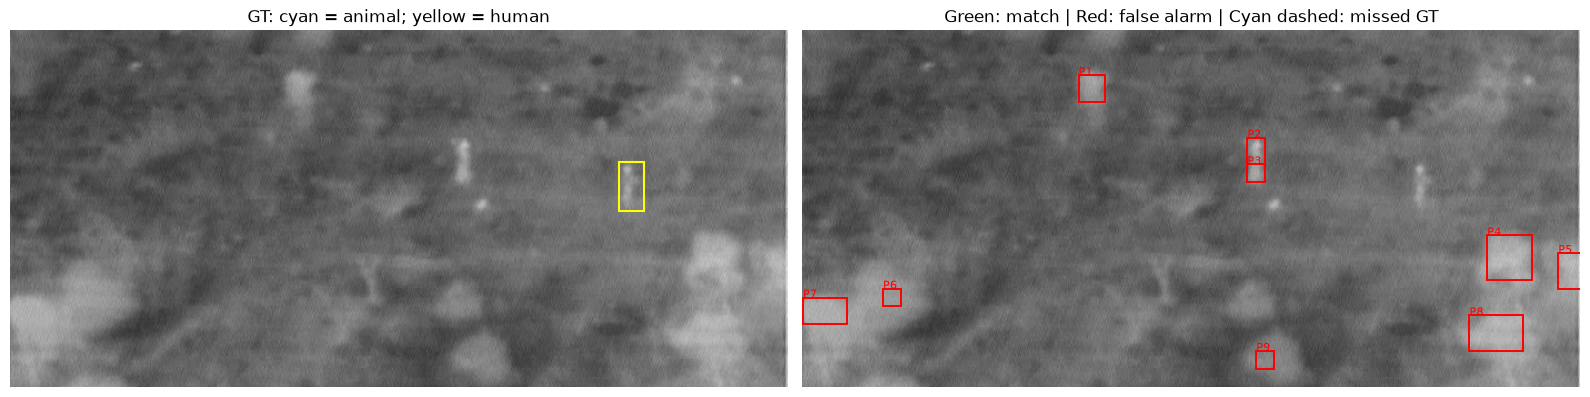

In [28]:
# Cell 28 — Show correct matches, false alarms and missed animals
# Output: Prediction-vs-GT overlay, including every false alarm and missed animal.
matched_p={i for i,j,v in matched};matched_g={j for i,j,v in matched}
fig,axes=plt.subplots(1,2,figsize=(16,5))
for ax in axes:ax.imshow(original,cmap='gray',vmin=0,vmax=1);ax.axis('off')
for j,b in gt.iterrows():
    axes[0].add_patch(Rectangle((b.x,b.y),b.width,b.height,fill=False,color='cyan',lw=2))
    axes[0].text(b.x,b.y,f'GT {int(b.track_id)}',color='cyan',fontsize=8)
for i,b in candidates.iterrows():
    color_now='lime' if i in matched_p else 'red'
    axes[1].add_patch(Rectangle((b.x,b.y),b.width,b.height,fill=False,color=color_now,lw=1.4))
    axes[1].text(b.x,b.y,f'P{int(b.candidate_id)}',color=color_now,fontsize=8)
for j,b in gt.iterrows():
    if j not in matched_g:axes[1].add_patch(Rectangle((b.x,b.y),b.width,b.height,fill=False,color='cyan',lw=2,linestyle='--'))
for b in human_gt.itertuples():
    axes[0].add_patch(Rectangle((b.x,b.y),b.width,b.height,fill=False,color='yellow',lw=1.5))
axes[0].set_title('GT: cyan = animal; yellow = human')
axes[1].set_title('Green: match | Red: false alarm | Cyan dashed: missed GT')
savefig('full_image_detection_errors')


In [29]:
# Cell 29 — Final full-image result and checks
# Output: Honest final summary, saved predictions and numerical integrity checks.
assert prediction['gt_used_for_prediction'] is False and (coverage>0).all()
assert TP+FP==len(candidates) and TP+FN==len(gt)
assert len({i for i,j,v in matched})==len(matched)==len({j for i,j,v in matched})
assert hashlib.sha256((OUT/'prediction_before_gt.json').read_bytes()).hexdigest()==PREDICTION_HASH
summary=dict(input=manifest,pipeline=prediction['pipeline'],settings=CFG,training_frames=60,training_animal_patches=535,
             training_background_patches=1440,prediction=prediction,object_evaluation=object_result.iloc[0].to_dict(),
             window_evaluation=window_result.iloc[0].to_dict(),presence_correct=bool(presence.iloc[0]['correct']),
             limitations=['Two hand-specified sequence cases; not a representative benchmark','GT boxes are not pixel masks','Background assumes complete GT',
                          'Adjacent positive windows can merge several animals','No test-image tuning or GT-guided proposals'])
def clean_json(v):
    if isinstance(v,dict):return {k:clean_json(x) for k,x in v.items()}
    if isinstance(v,list):return [clean_json(x) for x in v]
    if hasattr(v,'item'):v=v.item()
    if isinstance(v,float) and not np.isfinite(v):return None
    return v
summary=clean_json(summary)
(OUT/'FULL_IMAGE_SUMMARY.json').write_text(json.dumps(summary,indent=2,allow_nan=False))
print('Prediction:', 'animal detected' if ANIMAL_PRESENT else 'no animal detected')
print(f'Object results at IoU 0.5: TP={TP}, FP={FP}, FN={FN}')
print('Read image presence, object localization and full-scan window scores as THREE different results.')
print('This test may be harder than the earlier selected-patch test. Report failures too.')
print('All files saved in:',OUT.resolve())


Prediction: animal detected
Object results at IoU 0.5: TP=0, FP=9, FN=0
Read image presence, object localization and full-scan window scores as THREE different results.
This test may be harder than the earlier selected-patch test. Report failures too.
All files saved in: /Users/yingying/.codex/.chatgpt-projects/g-p-6a9853e50250819194465d3e0ed1452b/output/Wildlife_Full_Image_Evaluation/results/negative_human_sequence


In [30]:
# Cell 30 — Compare the two unseen cases
# Output: Both yes/no decisions and honest object-level results.
results=[]
for case in ['positive_animal_sequence','negative_human_sequence']:
    data=json.loads((Path('results')/case/'FULL_IMAGE_SUMMARY.json').read_text())
    obj=data['object_evaluation'];win=data['window_evaluation']
    results.append(dict(case=case,image=data['input']['filename'],predicted_animal_present=data['prediction']['animal_present'],
       gt_animals=int(obj['gt_animals']),presence_correct=data['presence_correct'],candidate_regions=int(obj['predicted_regions']),
       object_TP=int(obj['TP']),object_FP=int(obj['FP']),object_FN=int(obj['FN']),object_precision=obj['precision'],
       object_recall=obj['recall'],object_f1=obj['f1'],window_accuracy=win['accuracy'],window_balanced_accuracy=win['balanced_accuracy']))
OUT=Path('results');table(pd.DataFrame(results),'TWO_CASE_FULL_IMAGE_EVALUATION')
print('A positive yes/no answer can be caused by false alarms. Check the candidate boxes too.')
print('No settings were changed using these test images. Their GT was read after predictions.')
print('The earlier selected-patch score is not a whole-image detection guarantee.')


,case,image,predicted_animal_present,gt_animals,presence_correct,candidate_regions,object_TP,object_FP,object_FN,object_precision,object_recall,object_f1,window_accuracy,window_balanced_accuracy
0,positive_animal_sequence,0000000351_0000000000_0000000071.jpg,True,9,True,21,3,18,6,0.142857,0.333333,0.2,0.946174,0.778942
1,negative_human_sequence,0000000364_0000000000_0000003978.jpg,True,0,False,9,0,9,0,0.000000,NaN,0.0,0.988793,NaN


A positive yes/no answer can be caused by false alarms. Check the candidate boxes too.
No settings were changed using these test images. Their GT was read after predictions.
The earlier selected-patch score is not a whole-image detection guarantee.
